# Exercise 4: Rock Crack Detection with a Convolutional Neural Network

- **Course:** PPGEEC2327, Special Topics in Intelligent Information Processing (AI applied to Geophysics), UFRN
- **Reference:** Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Chapters 8 and 9
- **Task:** reproduce the rock-crack classification lab with a convolutional neural network (CNN) and interpret
  the results. The assignment text mentions AlexNet, but the official lab code (`test_example_CNN.m`) implements
  a small, from-scratch CNN with two convolutional layers, not AlexNet; this notebook follows the official code,
  which is what is actually distributed with the lab.
- **Materials:** the official lab page returns a TLS certificate error over HTTPS but is reachable over plain
  HTTP. The full `CNN_lab.zip` archive, including the real input image and the real labeled training points,
  was downloaded from there and is mirrored at `materials/CNN_crack_lab/CNN_lab`. All results below use that
  real data; no synthetic image is used.

## 1. Loading the official data

`image_input.mat` holds a 457 x 977 grayscale outcrop photo, already rescaled to [-1, 1]. `train_new.mat` holds
400 hand-picked training points: `trainx`/`trainz` are pixel coordinates, and `label` is a 2 x 400 one-hot
matrix (row 0 = crack, row 1 = non-crack), matching Code 10.5.1's `ntrain = 200` crack points followed by 200
non-crack points.

Image size: 457 x 977
Training points: 400 (200 crack, 200 non-crack)


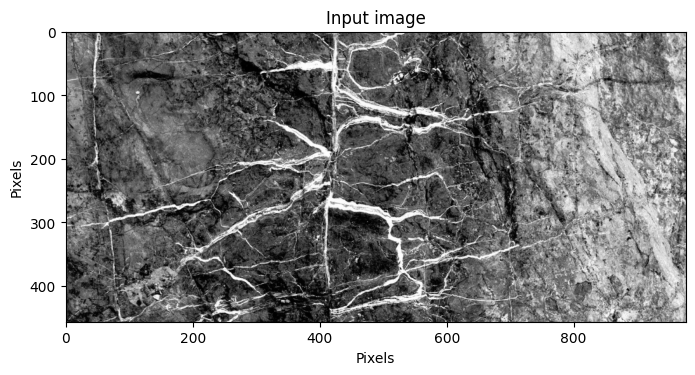

In [1]:
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt

DATA_DIR = "materials/CNN_crack_lab/CNN_lab/data"

image_input = sio.loadmat(f"{DATA_DIR}/image_input.mat")["image_input"].astype(np.float32)
train_mat = sio.loadmat(f"{DATA_DIR}/train_new.mat", struct_as_record=False, squeeze_me=True)["train"]
trainx = train_mat.trainx.astype(int)
trainz = train_mat.trainz.astype(int)
label = train_mat.label.astype(np.float32)  # (2, 400)

nz, nx = image_input.shape
print(f"Image size: {nz} x {nx}")
print(f"Training points: {trainx.shape[0]} ({int(label[0].sum())} crack, {int(label[1].sum())} non-crack)")

plt.figure(figsize=(8, 4))
plt.imshow(image_input, cmap="gray")
plt.title("Input image")
plt.xlabel("Pixels")
plt.ylabel("Pixels")
plt.show()

## 2. Discrepancies between the book text and the official code

As with Exercise 3, the book's prose, its own table, and the distributed code do not all agree. Documented here
rather than silently resolved, since the code is what actually runs:

1. **Table 10.2** lists "5 conv. layers" and a "4x4" patch size for the crack-detection CNN. **Code 10.5.1**
   (and the real `cnnsetup.m`/`test_example_CNN.m` downloaded for this exercise) define only **two** convolutional
   layers, with **5x5** kernels (6 output maps, then 12). Figure 2's own caption in `lab.html` agrees with the
   code: "two convolutional layer and a fully connected layer."
2. **Section 10.5.2** describes picking "400 crack and 400 non-crack" patches. **Code 10.5.1** and `lab.html`'s
   own procedure text both say 200 of each (`ntrain = 200`), which also matches the real `train_new.mat` used
   below (200 + 200).
3. The assignment text names **AlexNet**; the official code trains a small custom CNN from scratch, not AlexNet.
   This notebook follows the code.

## 3. Extracting the 400 labeled patches

Each training point is the center of a 17x17 patch (`wdx = wdz = 8` in Code 10.5.1, so `image_x = image_z =
2*8+1 = 17`). The image is first padded by replicating its border (`padimage.m`), then each 17x17 patch is
resized to 32x32 by bilinear interpolation (`interp2` with a grid spanning the patch corner to corner, i.e.
aligned corners), matching Code 10.5.1's upsampling step before the CNN.

Training patches: torch.Size([400, 1, 32, 32])


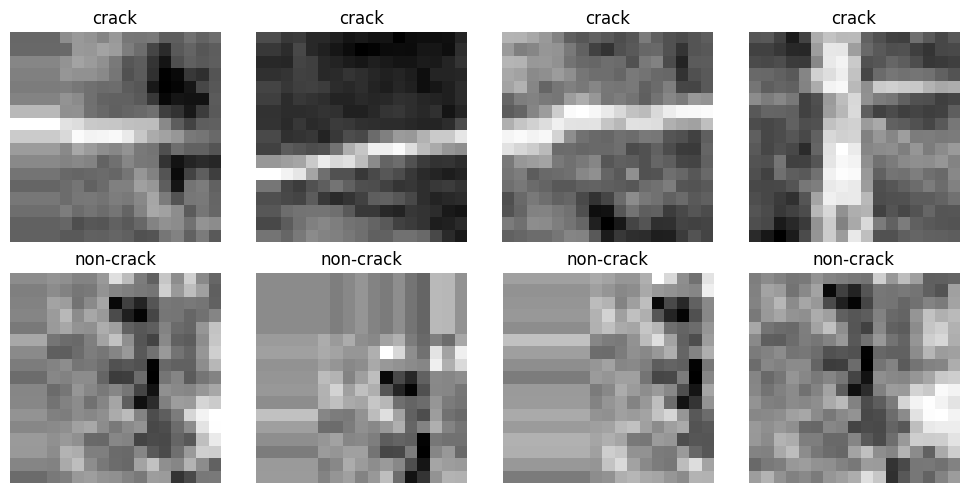

In [2]:
HALF = 8  # wdx = wdz = 8
PATCH = 2 * HALF + 1  # 17
RESIZED = 32

image_pad = np.pad(image_input, ((HALF, HALF), (HALF, HALF)), mode="edge")


def extract_patch(z1, x1):
    '''z1, x1 are 1-indexed MATLAB coordinates in the ORIGINAL image, matching
    image_pad(trainz:trainz+16, trainx:trainx+16) in test_example_CNN.m.'''
    z0, x0 = z1 - 1, x1 - 1
    return image_pad[z0:z0 + PATCH, x0:x0 + PATCH]


def resize_patches(patches):
    t = torch.tensor(patches, dtype=torch.float32).unsqueeze(1)
    return F.interpolate(t, size=(RESIZED, RESIZED), mode="bilinear", align_corners=True)


train_patches = np.stack([extract_patch(z, x) for z, x in zip(trainz, trainx)])
train_patches_resized = resize_patches(train_patches)
train_labels = torch.tensor(label.T, dtype=torch.float32)
print("Training patches:", train_patches_resized.shape)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
crack_idx = np.where(label[0] == 1)[0][:4]
noncrack_idx = np.where(label[1] == 1)[0][:4]
for col, idx in enumerate(crack_idx):
    axes[0, col].imshow(train_patches[idx], cmap="gray")
    axes[0, col].set_title("crack")
for col, idx in enumerate(noncrack_idx):
    axes[1, col].imshow(train_patches[idx], cmap="gray")
    axes[1, col].set_title("non-crack")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. CNN architecture and training

Matching `cnnsetup.m` / `cnnff.m` / `cnnbp.m` exactly: conv(1->6, 5x5) + sigmoid + average-pool(2), then
conv(6->12, 5x5) + sigmoid + average-pool(2), flattened into a fully connected layer to 2 outputs with a final
sigmoid (`net.o = sigm(...)` in `cnnff.m`). The loss is the quadratic misfit from `lab.html` Section 5
(`cnnbp.m`'s `net.L = 1/2 * sum(net.e.^2) / size(net.e,2)`), optimized with plain gradient descent
(`cnnapplygrads.m`). Hyperparameters are taken directly from `test_example_CNN.m`: `opts.alpha = 1` (learning
rate), `opts.batchsize = 20`, `opts.numepochs = 10`.

In [3]:
class CrackCNN(nn.Module):
    '''Two conv layers (6, 12 output maps; 5x5 kernels) with sigmoid + average pooling,
    then a fully connected sigmoid output layer, matching cnnsetup.m / cnnff.m.'''

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 12, 5)
        self.fc = nn.Linear(12 * 5 * 5, 2)

    def forward(self, x):
        x = torch.sigmoid(self.conv1(x))
        x = F.avg_pool2d(x, 2)
        x = torch.sigmoid(self.conv2(x))
        x = F.avg_pool2d(x, 2)
        x = x.flatten(1)
        return torch.sigmoid(self.fc(x))


def train_cnn(model, patches, labels, alpha=1.0, batch_size=20, epochs=10, seed=0, verbose=True):
    opt = torch.optim.SGD(model.parameters(), lr=alpha)
    rng = np.random.default_rng(seed)
    n = patches.shape[0]
    for epoch in range(epochs):
        perm = rng.permutation(n)
        total_loss = 0.0
        for b in range(0, n, batch_size):
            idx = perm[b:b + batch_size]
            opt.zero_grad()
            pred = model(patches[idx])
            loss = F.mse_loss(pred, labels[idx])
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(idx)
        if verbose:
            print(f"epoch {epoch + 1}/{epochs}  loss={total_loss / n:.4f}")
    return model


torch.manual_seed(0)
model = CrackCNN()
train_cnn(model, train_patches_resized, train_labels)

with torch.no_grad():
    pred = model(train_patches_resized)
    train_acc = (pred.argmax(1) == train_labels.argmax(1)).float().mean().item()
print(f"Training accuracy after 10 epochs: {train_acc:.1%}")

epoch 1/10  loss=0.2734
epoch 2/10  loss=0.2525
epoch 3/10  loss=0.2536
epoch 4/10  loss=0.2524
epoch 5/10  loss=0.2471
epoch 6/10  loss=0.2365
epoch 7/10  loss=0.2120


epoch 8/10  loss=0.1813
epoch 9/10  loss=0.1556
epoch 10/10  loss=0.1364
Training accuracy after 10 epochs: 83.5%


## 5. Classifying every pixel of the image

`test_example_CNN.m` applies the trained CNN to a 17x17 patch centered at every pixel of the image (in chunks,
to limit memory). The same sliding-window extraction and resizing is used here, run in batches of 4096 patches.

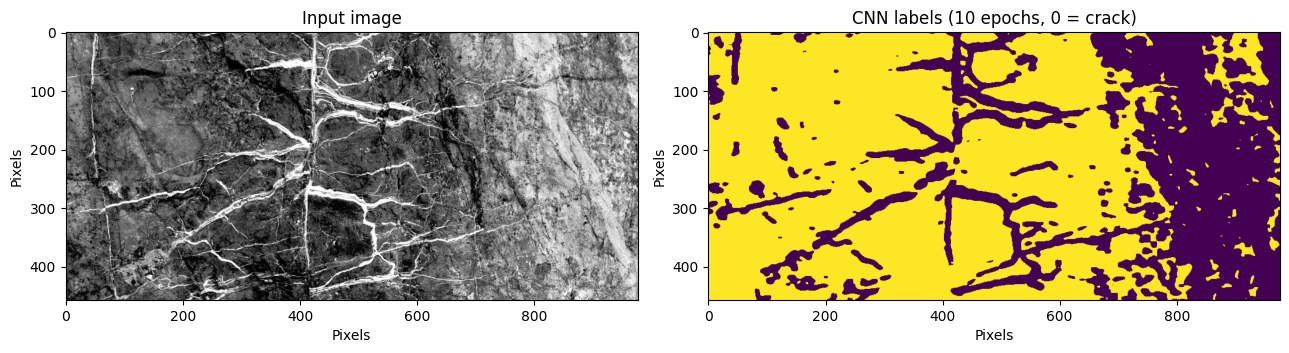

Fraction of the image classified as crack: 35.2%


In [4]:
def classify_full_image(model, chunk_size=4096):
    windows = sliding_window_view(image_pad, (PATCH, PATCH)).reshape(nz * nx, PATCH, PATCH)
    pred_map = np.zeros(nz * nx, dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for start in range(0, windows.shape[0], chunk_size):
            batch = resize_patches(windows[start:start + chunk_size])
            pred_map[start:start + chunk_size] = model(batch).argmax(1).numpy()
    return pred_map.reshape(nz, nx)


label_map = classify_full_image(model)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(image_input, cmap="gray")
axes[0].set_title("Input image")
axes[1].imshow(label_map, cmap="viridis")
axes[1].set_title("CNN labels (10 epochs, 0 = crack)")
for ax in axes:
    ax.set_xlabel("Pixels")
    ax.set_ylabel("Pixels")
plt.tight_layout()
plt.show()

print(f"Fraction of the image classified as crack: {(label_map == 0).mean():.1%}")

## 6. Why the right third of the image is misclassified

The classification map tracks the visible crack network reasonably well on the left two-thirds of the image,
but labels nearly the entire right portion as crack, even though that region shows a different, unbroken rock
texture. The cause is visible directly in the official training set, not in the CNN: the 200 non-crack points
in `train_new.mat` are not spread across the image. They are confined to a 9x17-pixel corner.

Crack points: x in (np.int64(6), np.int64(792))  z in (np.int64(1), np.int64(453))
Non-crack points: x in (np.int64(1), np.int64(9))  z in (np.int64(1), np.int64(17))  ( 9 distinct x values )


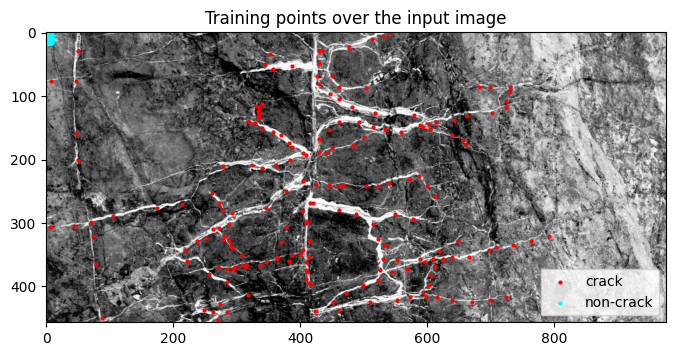

In [5]:
crack_mask = label[0] == 1
print("Crack points: x in", (trainx[crack_mask].min(), trainx[crack_mask].max()),
      " z in", (trainz[crack_mask].min(), trainz[crack_mask].max()))
print("Non-crack points: x in", (trainx[~crack_mask].min(), trainx[~crack_mask].max()),
      " z in", (trainz[~crack_mask].min(), trainz[~crack_mask].max()),
      " (", len(np.unique(trainx[~crack_mask])), "distinct x values )")

plt.figure(figsize=(8, 4))
plt.imshow(image_input, cmap="gray")
plt.scatter(trainx[crack_mask], trainz[crack_mask], s=4, c="red", label="crack")
plt.scatter(trainx[~crack_mask], trainz[~crack_mask], s=4, c="cyan", label="non-crack")
plt.legend(loc="lower right")
plt.title("Training points over the input image")
plt.show()

The non-crack class was sampled from a single small, uniform patch of background texture, repeated 200 times
with small jitter, instead of from a representative spread of non-crack regions. The CNN has never seen a
non-crack example resembling the brighter rock texture on the right, so it defaults to the other class there.
This is a property of the official training set, not an artifact of the Python port.

## 7. Section 6, Question 3: increasing the number of training iterations

`lab.html`'s own Section 6 asks: *"Increase the iteration number to 100. How the result will change? Why? Is
there anyway to prevent this problem."* `test_example_CNN.m` ships with `opts.numepochs = 10`; here the same
model is retrained from the same initialization for exactly 100 epochs instead, as the question literally asks,
and the resulting classification map is compared to the 10-epoch one above.


Training accuracy after 100 epochs: 100.0%


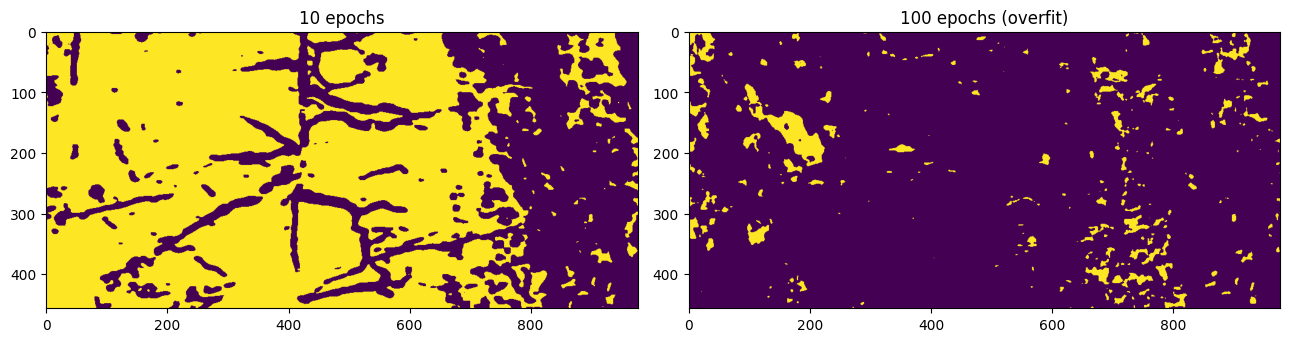

Crack fraction, 10 epochs: 35.2%
Crack fraction, 100 epochs: 94.3%


In [6]:
torch.manual_seed(0)
model_long = CrackCNN()
train_cnn(model_long, train_patches_resized, train_labels, epochs=100, verbose=False)

with torch.no_grad():
    pred_long = model_long(train_patches_resized)
    train_acc_long = (pred_long.argmax(1) == train_labels.argmax(1)).float().mean().item()
print(f"Training accuracy after 100 epochs: {train_acc_long:.1%}")

label_map_long = classify_full_image(model_long)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(label_map, cmap="viridis")
axes[0].set_title("10 epochs")
axes[1].imshow(label_map_long, cmap="viridis")
axes[1].set_title("100 epochs (overfit)")
plt.tight_layout()
plt.show()

print(f"Crack fraction, 10 epochs: {(label_map == 0).mean():.1%}")
print(f"Crack fraction, 100 epochs: {(label_map_long == 0).mean():.1%}")


## 8. Discussion: effect of training for 100 epochs

Training to 100% training accuracy (100 epochs) does not produce a better crack map; it produces a visibly
worse one. The 10-epoch model still traces the main crack network; the 100-epoch model instead fits fine
details of the 400 individual training patches and collapses into a map where almost the entire image reads as
crack.

This happens because the training set is small (400 patches) and, per Section 6 above, severely skewed: the
non-crack class is a single uniform texture. More iterations let the network memorize that narrow training
distribution instead of learning a decision boundary that generalizes, which is the overfitting the lab's own
question anticipates. `opts.numepochs = 10` in the official code is a reasonable stopping point given this
training set, not an arbitrary choice.

The fix is not fewer iterations but a better training set: non-crack points should be sampled from a spread of
regions and textures across the image (not one corner), and a held-out validation split would let training stop
when validation accuracy, not training accuracy, stops improving. Sections 9 to 11 below answer the lab's
remaining three Section 6 questions and reproduce the same overfitting pattern again, from different angles.


## 9. Section 6, Question 1: picking the training set by crack size

`lab.html`'s Section 6 also asks to pick the training set manually, focusing on big cracks only or small cracks
only, to see how the result looks. `train_new.mat` has no crack-size label, and clicking a fresh training set
by hand is not reproducible in a notebook (the same limitation documented in Section 2 for Exercise 3's
training set). Instead, the existing 200 official crack points are split into "big" and "small" groups using a
distance-based proxy: two crack points are linked if they are within 25 pixels of each other, and the resulting
connected components are treated as individual crack traces. The 5 largest components (43, 27, 15, 10, and 10
points) are taken as the "big crack" points; every other crack point, mostly small isolated components, is the
"small crack" set. This treats a crack drawn with many closely spaced clicks as a "big" crack and a crack
clicked only once or twice as a "small" one, which is the closest available substitute for a size label.

big-crack points: 105, small-crack points: 95


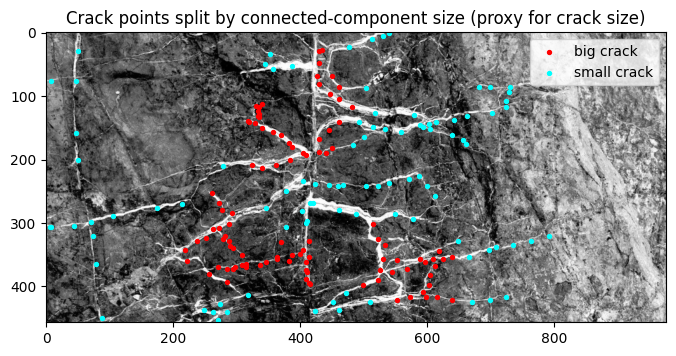

epoch 1/30  loss=0.2985


epoch 2/30  loss=0.2396
epoch 3/30  loss=0.2332
epoch 4/30  loss=0.2293


epoch 5/30  loss=0.2272
epoch 6/30  loss=0.2291
epoch 7/30  loss=0.2287
epoch 8/30  loss=0.2263


epoch 9/30  loss=0.2275
epoch 10/30  loss=0.2257


epoch 11/30  loss=0.2255
epoch 12/30  loss=0.2257
epoch 13/30  loss=0.2254


...

epoch 29/30  loss=0.0648
epoch 30/30  loss=0.0520


epoch 1/30  loss=0.2566
epoch 2/30  loss=0.2425
epoch 3/30  loss=0.2204
epoch 4/30  loss=0.2160
epoch 5/30  loss=0.2095
epoch 6/30  loss=0.2160
epoch 7/30  loss=0.2019
epoch 8/30  loss=0.1966
epoch 9/30  loss=0.1920


epoch 10/30  loss=0.1796
epoch 11/30  loss=0.1568
epoch 12/30  loss=0.1401
epoch 13/30  loss=0.1199
epoch 14/30  loss=0.1111
epoch 15/30  loss=0.1221
epoch 16/30  loss=0.1046
epoch 17/30  loss=0.0889
epoch 18/30  loss=0.0807
epoch 19/30  loss=0.0774


epoch 20/30  loss=0.0543
epoch 21/30  loss=0.0583
epoch 22/30  loss=0.0496
epoch 23/30  loss=0.0404
epoch 24/30  loss=0.0307
epoch 25/30  loss=0.0236
epoch 26/30  loss=0.0194
epoch 27/30  loss=0.0244
epoch 28/30  loss=0.0154


epoch 29/30  loss=0.0123
epoch 30/30  loss=0.0115


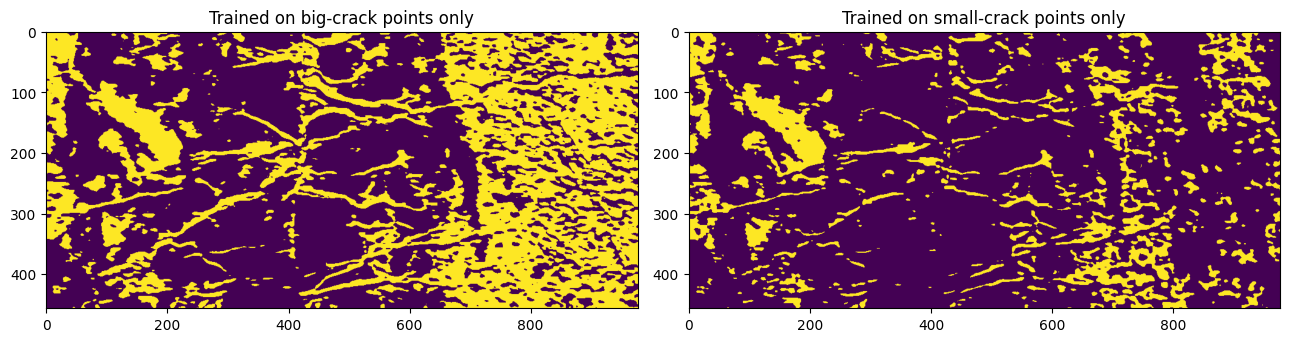

Crack fraction, big-crack-only training: 60.4%
Crack fraction, small-crack-only training: 81.7%
Crack fraction, full training set (Section 5, 10 epochs): 35.2%
Pixel agreement, big-only vs small-only: 77.7%
Pixel agreement, big-only vs full set: 35.6%
Pixel agreement, small-only vs full set: 47.8%


In [7]:
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix

crack_idx_all = np.where(label[0] == 1)[0]
noncrack_idx_all = np.where(label[1] == 1)[0]
cx, cz = trainx[crack_idx_all], trainz[crack_idx_all]

dist = np.sqrt((cx[:, None] - cx[None, :]) ** 2 + (cz[:, None] - cz[None, :]) ** 2)
adjacency = (dist < 25).astype(int)
np.fill_diagonal(adjacency, 0)
n_components, component_id = connected_components(csr_matrix(adjacency), directed=False)
component_size = np.bincount(component_id)
big_components = set(np.argsort(component_size)[::-1][:5])
is_big = np.isin(component_id, list(big_components))

big_crack_idx = crack_idx_all[is_big]
small_crack_idx = crack_idx_all[~is_big]
print(f"big-crack points: {len(big_crack_idx)}, small-crack points: {len(small_crack_idx)}")

plt.figure(figsize=(8, 4))
plt.imshow(image_input, cmap="gray")
plt.scatter(trainx[big_crack_idx], trainz[big_crack_idx], s=8, c="red", label="big crack")
plt.scatter(trainx[small_crack_idx], trainz[small_crack_idx], s=8, c="cyan", label="small crack")
plt.legend()
plt.title("Crack points split by connected-component size (proxy for crack size)")
plt.show()


def build_subset(crack_idx_subset):
    idx = np.concatenate([crack_idx_subset, noncrack_idx_all])
    patches = resize_patches(np.stack([extract_patch(trainz[i], trainx[i]) for i in idx]))
    lab = np.zeros((len(idx), 2), dtype=np.float32)
    lab[:len(crack_idx_subset), 0] = 1.0
    lab[len(crack_idx_subset):, 1] = 1.0
    return patches, torch.tensor(lab)


patches_big, labels_big = build_subset(big_crack_idx)
patches_small, labels_small = build_subset(small_crack_idx)

# 30 epochs instead of the baseline's 10: these subsets are smaller and more imbalanced than the
# official 200/200 split, and 10 epochs is not enough to get past the slow start also visible in
# Section 4's own loss curve (epochs 1-6 stuck near 0.25 before dropping). Verified directly: after
# 10 epochs, training accuracy reaches only 65.6% on the big-crack subset and 78.3% on the
# small-crack one, both well short of the near-100% reached by epoch 30 below.
torch.manual_seed(0)
model_big = CrackCNN()
train_cnn(model_big, patches_big, labels_big, epochs=30)
label_map_big = classify_full_image(model_big)

torch.manual_seed(0)
model_small = CrackCNN()
train_cnn(model_small, patches_small, labels_small, epochs=30)
label_map_small = classify_full_image(model_small)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(label_map_big, cmap="viridis")
axes[0].set_title("Trained on big-crack points only")
axes[1].imshow(label_map_small, cmap="viridis")
axes[1].set_title("Trained on small-crack points only")
plt.tight_layout()
plt.show()

print(f"Crack fraction, big-crack-only training: {(label_map_big == 0).mean():.1%}")
print(f"Crack fraction, small-crack-only training: {(label_map_small == 0).mean():.1%}")
print(f"Crack fraction, full training set (Section 5, 10 epochs): {(label_map == 0).mean():.1%}")
print(f"Pixel agreement, big-only vs small-only: {(label_map_big == label_map_small).mean():.1%}")
print(f"Pixel agreement, big-only vs full set: {(label_map_big == label_map).mean():.1%}")
print(f"Pixel agreement, small-only vs full set: {(label_map_small == label_map).mean():.1%}")

Both size-restricted models classify a much larger fraction of the image as crack than the full-set model
does (printed above), and they agree with that full-set model on well under half the image. Restricting the
crack class to only "big" or only "small" examples does not sharpen the model's notion of crack texture, it
shrinks and skews the crack-side training data (105 or 95 points instead of 200, now needing 30 epochs instead
of 10 just to leave the training plateau from Section 4), which pushes the model toward the same kind of
overfitting already seen in Section 8 with 100 epochs: once training accuracy gets high on a small, narrow
sample, the decision boundary generalizes poorly to the rest of the image. Training on big cracks only pulls
the boundary toward the texture of those few long, clustered traces, while training on small cracks only pulls
it toward isolated point-like features, and neither matches the full, size-mixed crack population the complete
200-point set represents.

## 10. Section 6, Question 2: modifying the CNN architecture

`lab.html`'s Section 6 also asks to modify the CNN architecture to see how its parameters change the result.
The baseline network (Section 4) uses 6 then 12 convolutional filters with average pooling. Here both filter
counts are increased to 16 and 32 and average pooling is replaced with max pooling, a substantially
higher-capacity network (14,850 trainable parameters against the baseline's 2,570), trained from the same
initialization scheme and on the same 400 official training patches.

Parameter count: baseline=2570, wide=14850
epoch 1/30  loss=0.4804
epoch 2/30  loss=0.4998
epoch 3/30  loss=0.4994


epoch 4/30  loss=0.3837
epoch 5/30  loss=0.2512
epoch 6/30  loss=0.2516
epoch 7/30  loss=0.2518


epoch 8/30  loss=0.2510
epoch 9/30  loss=0.2525
epoch 10/30  loss=0.2479
epoch 11/30  loss=0.2233


epoch 12/30  loss=0.1875
epoch 13/30  loss=0.1430
epoch 14/30  loss=0.1064
epoch 15/30  loss=0.0959


epoch 16/30  loss=0.0798
epoch 17/30  loss=0.0829
epoch 18/30  loss=0.0753
epoch 19/30  loss=0.0544


epoch 20/30  loss=0.0476
epoch 21/30  loss=0.0430
epoch 22/30  loss=0.0456
epoch 23/30  loss=0.0359


epoch 24/30  loss=0.0277
epoch 25/30  loss=0.0276
epoch 26/30  loss=0.0217
epoch 27/30  loss=0.0205


epoch 28/30  loss=0.0178
epoch 29/30  loss=0.0156
epoch 30/30  loss=0.0135
Training accuracy, wide architecture (30 epochs): 99.0%


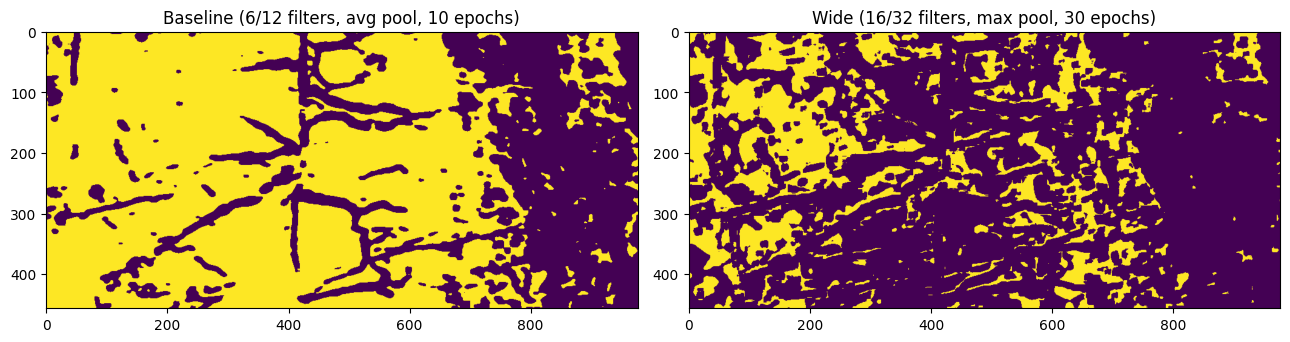

Crack fraction, wide architecture: 76.7%
Pixel agreement, wide vs baseline: 58.5%


In [8]:
class CrackCNNWide(nn.Module):
    """Wider architecture: 16 and 32 filters (vs 6 and 12) with max pooling (vs average pooling)."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 5)
        self.conv2 = nn.Conv2d(16, 32, 5)
        self.fc = nn.Linear(32 * 5 * 5, 2)

    def forward(self, x):
        x = torch.sigmoid(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = torch.sigmoid(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = x.flatten(1)
        return torch.sigmoid(self.fc(x))


n_params_baseline = sum(p.numel() for p in CrackCNN().parameters())
n_params_wide = sum(p.numel() for p in CrackCNNWide().parameters())
print(f"Parameter count: baseline={n_params_baseline}, wide={n_params_wide}")

# 30 epochs: same reasoning as Section 9, the wider network has not gotten past its own slow
# start after 10 epochs either (46.0% training accuracy, verified directly, against 83.5% for the
# baseline at 10 epochs).
torch.manual_seed(0)
model_wide = CrackCNNWide()
train_cnn(model_wide, train_patches_resized, train_labels, epochs=30)

with torch.no_grad():
    pred_wide = model_wide(train_patches_resized)
    train_acc_wide = (pred_wide.argmax(1) == train_labels.argmax(1)).float().mean().item()
print(f"Training accuracy, wide architecture (30 epochs): {train_acc_wide:.1%}")

label_map_wide = classify_full_image(model_wide)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(label_map, cmap="viridis")
axes[0].set_title("Baseline (6/12 filters, avg pool, 10 epochs)")
axes[1].imshow(label_map_wide, cmap="viridis")
axes[1].set_title("Wide (16/32 filters, max pool, 30 epochs)")
plt.tight_layout()
plt.show()

print(f"Crack fraction, wide architecture: {(label_map_wide == 0).mean():.1%}")
print(f"Pixel agreement, wide vs baseline: {(label_map_wide == label_map).mean():.1%}")

The wider network reaches near-perfect training accuracy, well above the baseline's (Section 4), but its
classification map covers a much larger fraction of the image as crack and agrees with the baseline on a little
over half the pixels. More filters and max pooling, instead of average pooling, give the network far more
capacity to fit the 400 training patches exactly, including the single uniform non-crack texture described in
Section 6, with the same overfitting consequence already identified for longer training in Section 8: extra
capacity reduces training loss faster but does not add information the small, skewed training set does not
already contain, so the full-image prediction degrades. Changing the architecture here acts like changing the
iteration count: both let the model fit the training patches more exactly without changing what those patches
can teach it about the image as a whole.

## 11. Section 6, Question 4: multi-class classification (background, crack 1, crack 2)

`lab.html`'s Section 6 finally asks to try multi-class classification, for example background, crack class 1,
and crack class 2. The big-crack and small-crack groups from Section 9 are reused as "crack class 1" and "crack
class 2" respectively, together with the official 200 non-crack points as "background", giving a 3-class
problem. The network is the baseline `CrackCNN` architecture with its output layer widened from 2 to 3 units;
everything else (loss, optimizer, patch extraction) is unchanged.

epoch 1/30  loss=0.2239
epoch 2/30  loss=0.2112
epoch 3/30  loss=0.2131
epoch 4/30  loss=0.2117
epoch 5/30  loss=0.2085


epoch 6/30  loss=0.2089
epoch 7/30  loss=0.2089


epoch 8/30  loss=0.2083
epoch 9/30  loss=0.2078
epoch 10/30  loss=0.2068
epoch 11/30  loss=0.2058


epoch 12/30  loss=0.2031
epoch 13/30  loss=0.2015
epoch 14/30  loss=0.1980


epoch 15/30  loss=0.1943
epoch 16/30  loss=0.1902
epoch 17/30  loss=0.1841
epoch 18/30  loss=0.1800


epoch 19/30  loss=0.1731
epoch 20/30  loss=0.1664
epoch 21/30  loss=0.1640


epoch 22/30  loss=0.1511
epoch 23/30  loss=0.1406
epoch 24/30  loss=0.1295
epoch 25/30  loss=0.1182


epoch 26/30  loss=0.1105
epoch 27/30  loss=0.1035
epoch 28/30  loss=0.0981


epoch 29/30  loss=0.1032
epoch 30/30  loss=0.0952
Training accuracy, 3-class model (30 epochs): 81.2%


crack class 1 (big): 324794 pixels (72.7%)
crack class 2 (small): 39638 pixels (8.9%)
background: 82057 pixels (18.4%)


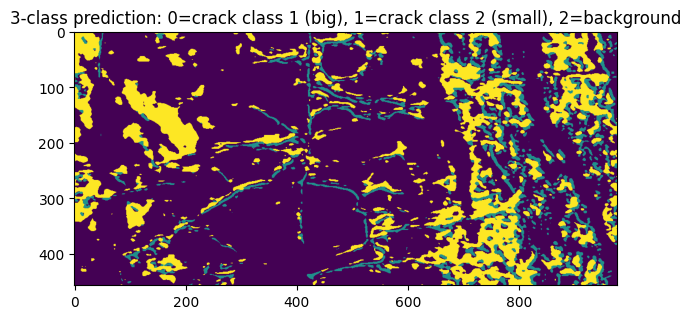

In [9]:
class CrackCNN3(nn.Module):
    """Same architecture as CrackCNN (Section 4), with a 3-way output for background/crack1/crack2."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 12, 5)
        self.fc = nn.Linear(12 * 5 * 5, 3)

    def forward(self, x):
        x = torch.sigmoid(self.conv1(x))
        x = F.avg_pool2d(x, 2)
        x = torch.sigmoid(self.conv2(x))
        x = F.avg_pool2d(x, 2)
        x = x.flatten(1)
        return torch.sigmoid(self.fc(x))


mc_idx = np.concatenate([big_crack_idx, small_crack_idx, noncrack_idx_all])
patches_mc = resize_patches(np.stack([extract_patch(trainz[i], trainx[i]) for i in mc_idx]))
labels_mc_arr = np.zeros((len(mc_idx), 3), dtype=np.float32)
labels_mc_arr[:len(big_crack_idx), 0] = 1.0  # crack class 1 = big crack
labels_mc_arr[len(big_crack_idx):len(big_crack_idx) + len(small_crack_idx), 1] = 1.0  # crack class 2 = small crack
labels_mc_arr[len(big_crack_idx) + len(small_crack_idx):, 2] = 1.0  # background
labels_mc = torch.tensor(labels_mc_arr)

torch.manual_seed(0)
model_mc = CrackCNN3()
train_cnn(model_mc, patches_mc, labels_mc, epochs=30)

with torch.no_grad():
    pred_mc = model_mc(patches_mc)
    train_acc_mc = (pred_mc.argmax(1) == labels_mc.argmax(1)).float().mean().item()
print(f"Training accuracy, 3-class model (30 epochs): {train_acc_mc:.1%}")


def classify_full_image_3(model, chunk_size=4096):
    windows = sliding_window_view(image_pad, (PATCH, PATCH)).reshape(nz * nx, PATCH, PATCH)
    pred_map = np.zeros(nz * nx, dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for start in range(0, windows.shape[0], chunk_size):
            batch = resize_patches(windows[start:start + chunk_size])
            pred_map[start:start + chunk_size] = model(batch).argmax(1).numpy()
    return pred_map.reshape(nz, nx)


label_map_mc = classify_full_image_3(model_mc)
counts = np.bincount(label_map_mc.reshape(-1), minlength=3)
names = ["crack class 1 (big)", "crack class 2 (small)", "background"]
for name, count in zip(names, counts):
    print(f"{name}: {count} pixels ({100 * count / counts.sum():.1f}%)")

plt.figure(figsize=(7, 4))
plt.imshow(label_map_mc, cmap="viridis")
plt.title("3-class prediction: 0=crack class 1 (big), 1=crack class 2 (small), 2=background")
plt.show()

The 3-class model assigns most of the image to crack class 1 (the "big crack" class), a much smaller share
to crack class 2, and the rest to background. That split is consistent with Section 9's finding for the
2-class big-crack-only model, which also classified most of the image as crack: the training set still has
only a single uniform, 200-point background sample (Section 6) and now splits its crack examples across two
classes instead of one, so there is even less information for the network to tell either crack class apart
from background in regions unlike anything it saw during training. Going from 2 classes to 3 does not fix the
training-set problem described throughout this notebook; it just distributes the same overfitting pattern
across one more output unit.

## 12. Summary of the Section 6 questions

All three variations tried in Sections 9 to 11, picking crack-only or non-crack-only training points by size,
widening the CNN, and adding a third class, reproduce the same overfitting pattern identified in Section 8 for
longer training: every one of these models ends up covering a much larger, visually implausible share of the
image as crack than the 10-epoch baseline. Pixel agreement with that baseline ranges from about a third
(big-crack-only training) to a little over half (the wider architecture), and the 3-class model splits its
crack prediction unevenly across two output classes rather than matching the baseline pixel for pixel at all.
That is a direct consequence of `train_new.mat`'s training set itself (Section 6), not of any one
hyperparameter: 400 points, 200 of them a single uniform patch of background texture, is too little and too
narrow a sample to support a bigger model, more classes, or more training time without memorizing that narrow
sample instead of generalizing from it.